In [1]:
SEED = 42
import torch
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [2]:
from pathlib import Path
import sys

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [3]:
import numpy as np
import pandas as pd
import time
from src.preprocessing.scaler import split_val, scale_flat 

train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

In [4]:
X_train, X_val, y_train, y_val = split_val(X=X_train,y=y_train, val_size=0.1, seed=SEED)
X_train, X_val, X_test,tools = scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode='standard')
print(f'Train: {len(X_train)}, Test: {len(X_test)}, Val: {len(X_val)}')

Global Mean: 0.1307, Global Std: 0.3082
Train: 54000, Test: 10000, Val: 6000


In [5]:
from src.models.mlp import MLP
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import GaussianNaiveBayes
from src.evaluation.metrics import ClassificationMetrics

import matplotlib.pyplot as plt
import seaborn as sns

## TRAIN LOGISTIC REGRESSION với best config

In [6]:
SEED = 42
trained_models = {'model name' : [], 'models' : [], 'accuracy' : [], 'time train (s)': [], 'time pred (s)' : [], 'reports' : []}

In [7]:
BEST_EPOCH = 26 # đã tìm đc ở file thí nghiệm

LR_FIXED_PARAMS = {
    "max_epochs": BEST_EPOCH,
    "batch_size": 128,
    "patience": 6,
    "seed": SEED
}

BEST_CONFIG = {
    "eta" : 0.03,
    "lam" : 0.001,
}
    
model_lr = LogisticRegression(
    **LR_FIXED_PARAMS,
    eta=BEST_CONFIG['eta'],
    lam=BEST_CONFIG['lam']
)

start = time.perf_counter()
model_lr.fit(X_train, y_train, X_val=X_val, y_val=y_val)
time_lr_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_lr = model_lr.predict(X_test)
time_lr_pred = time.perf_counter() - start

# TEST TREN TAP TEST
metrics_lr = ClassificationMetrics(y_pred=y_pred_lr, y_true=y_test)
report_lr = metrics_lr.evaluate()

print(f"ACCURACY: {report_lr['accuracy']}, MACRO RECALL: {report_lr['macro_recall']}")
print(f"Thời gian huấn luyện LR: {time_lr_train:.3f} giây")
print(f"Thời gian dự đoán LR: {time_lr_pred:.3f} giây")


# Lưu lại vào dict
trained_models['model name'].append('Logistic Regression')
trained_models['models'].append(model_lr)
trained_models['accuracy'].append(report_lr['accuracy'])
trained_models['time train (s)'].append(f"{time_lr_train:.3f}")
trained_models['time pred (s)'].append(f"{time_lr_pred:.3f}")
trained_models['reports'].append(report_lr)

ACCURACY: 0.9254, MACRO RECALL: 0.924316213274091
Thời gian huấn luyện LR: 6.208 giây
Thời gian dự đoán LR: 0.024 giây


## SOME VISUALIZATIONS OF LOGISTIC MODEL

In [8]:
def plot_confusion_matrix(
    cm,
    class_names,
    title="Confusion Matrix",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
    cmap="Blues",
    figsize=(10, 8),
):
    """Vẽ confusion matrix với hàng là nhãn thật, cột là nhãn dự đoán."""
    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        cm,
        annot=True,
        fmt=".0f",
        cmap=cmap,
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        square=True,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )

    ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)

    ax.tick_params(axis="x", labelrotation=0)
    ax.tick_params(axis="y", labelrotation=0)

    fig.tight_layout()
    plt.show()

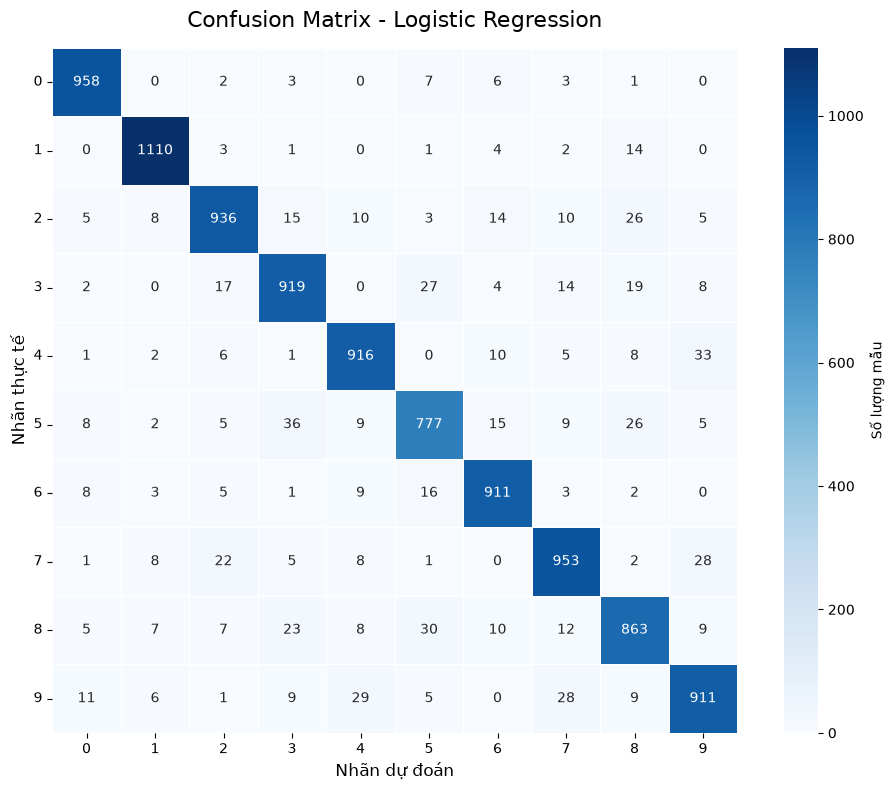

In [9]:
cm_lr, class_names = metrics_lr.get_confustion_matrix()

plot_confusion_matrix(
    cm=cm_lr,
    class_names=class_names,
    title="Confusion Matrix - Logistic Regression",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
)

## TRAIN GAUSSIAN NAIVE BAYES với best config

In [10]:
BEST_SMOOTHING = 1e-1

model_nb = GaussianNaiveBayes(BEST_SMOOTHING, batch_size=512)

start = time.perf_counter()
model_nb.fit(X=X_train, y=y_train)
time_nb_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_nb = model_nb.predict(X_test)
time_nb_pred = time.perf_counter() - start

# TEST TREN TAP TEST
metrics_nb = ClassificationMetrics(y_pred=y_pred_nb, y_true=y_test)
report_nb = metrics_nb.evaluate()

print(f"ACCURACY: {report_nb['accuracy']}, MACRO RECALL: {report_nb['macro_recall']}")
print(f"Thời gian huấn luyện NB: {time_nb_train:.3f} giây")
print(f"Thời gian dự đoán NB: {time_nb_pred:.3f} giây")


trained_models['model name'].append('Naive Bayess')
trained_models['models'].append(model_nb)
trained_models['accuracy'].append(report_nb['accuracy'])
trained_models['time train (s)'].append(f"{time_nb_train:.3f}")
trained_models['time pred (s)'].append(f"{time_nb_pred:.3f}")
trained_models['reports'].append(report_nb)

ACCURACY: 0.8149, MACRO RECALL: 0.8111573232383528
Thời gian huấn luyện NB: 0.414 giây
Thời gian dự đoán NB: 0.428 giây


## SOME VISUALIZATIONS OF GAUSSIAN NAIVE BAYESS

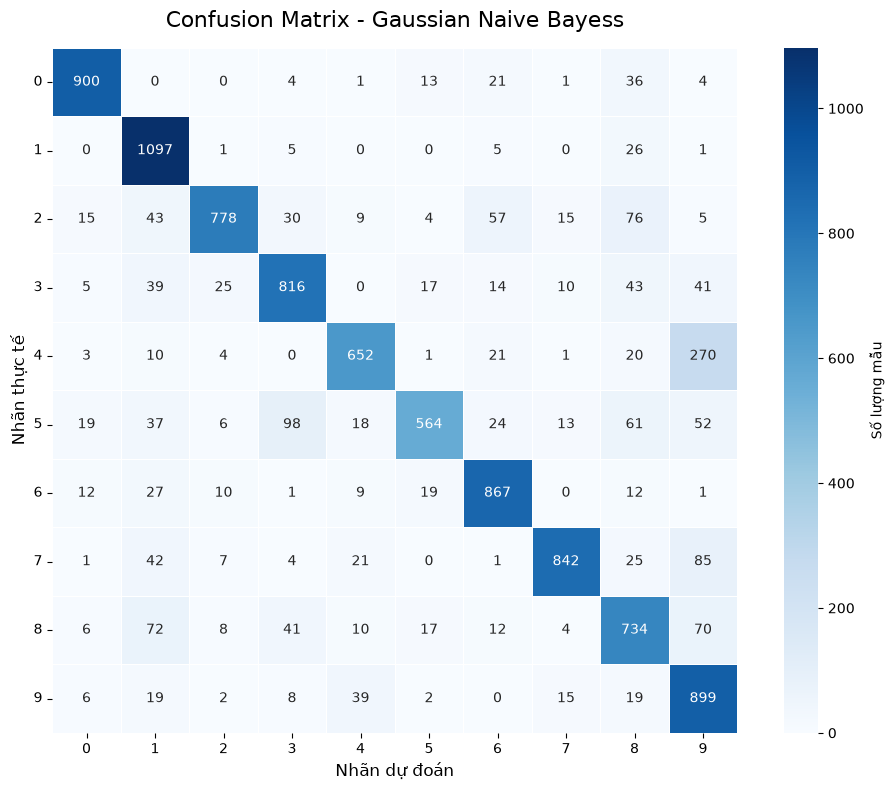

In [11]:
cm_nb, class_names_nb = metrics_nb.get_confustion_matrix()

plot_confusion_matrix(
    cm=cm_nb,
    class_names=class_names_nb,
    title="Confusion Matrix - Gaussian Naive Bayess",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
)

## TRAIN MLP MODEL

In [12]:
best_config_mlp = {
    "sizes": [784, 500, 10],
    "lr": 0.05,
    "momentum": 0.9,
    "p_drop": 0.0,
    "weight_decay": 0.0001,
    "batch_size": 128,
    "max_epochs": 37,
    "patience": 6
}

model_mlp = MLP(
    sizes=best_config_mlp['sizes'],
    activation='relu',
    p_drop=best_config_mlp['p_drop'],
    init='he',
    seed=SEED,
)

start = time.perf_counter()
hist_mlp = model_mlp.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=best_config_mlp['max_epochs'],
    batch_size=best_config_mlp['batch_size'],
    lr=best_config_mlp['lr'],
    patience=best_config_mlp['patience'],  # early stopping
    weight_decay=best_config_mlp['weight_decay'],
    momentum=best_config_mlp['momentum'],
    seed=SEED,
    verbose=True
)
time_mlp_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_mlp = model_mlp.predict(X_test)
time_mlp_pred = time.perf_counter() - start

# TEST TREN TAP TEST
metrics_mlp = ClassificationMetrics(y_pred=y_pred_mlp, y_true=y_test)
report_mlp = metrics_mlp.evaluate()

print(f"ACCURACY: {report_mlp['accuracy']}, MACRO RECALL: {report_mlp['macro_recall']}")
print(f"Time Train MLP: {time_mlp_train}")
print(f"Time Test MLP: {time_mlp_pred}")


trained_models['model name'].append('MLP')
trained_models['models'].append(model_mlp)
trained_models['accuracy'].append(report_mlp['accuracy'])
trained_models['time train (s)'].append(f"{time_mlp_train:.3f}")
trained_models['time pred (s)'].append(f"{time_mlp_pred:.3f}")
trained_models['reports'].append(report_mlp)

Epoch 01/37 | train loss 0.0939 acc 0.9697 | val loss 0.1340 acc 0.9590
Epoch 02/37 | train loss 0.0446 acc 0.9865 | val loss 0.1000 acc 0.9718
Epoch 03/37 | train loss 0.0266 acc 0.9919 | val loss 0.0922 acc 0.9733
Epoch 04/37 | train loss 0.0157 acc 0.9962 | val loss 0.0845 acc 0.9748
Epoch 05/37 | train loss 0.0110 acc 0.9972 | val loss 0.0813 acc 0.9807
Epoch 06/37 | train loss 0.0081 acc 0.9983 | val loss 0.0824 acc 0.9797
Epoch 07/37 | train loss 0.0058 acc 0.9993 | val loss 0.0758 acc 0.9812
Epoch 08/37 | train loss 0.0034 acc 0.9998 | val loss 0.0745 acc 0.9810
Epoch 09/37 | train loss 0.0022 acc 1.0000 | val loss 0.0753 acc 0.9827
Epoch 10/37 | train loss 0.0018 acc 1.0000 | val loss 0.0733 acc 0.9832
Epoch 11/37 | train loss 0.0022 acc 0.9999 | val loss 0.0755 acc 0.9828
Epoch 12/37 | train loss 0.0018 acc 1.0000 | val loss 0.0720 acc 0.9837
Epoch 13/37 | train loss 0.0017 acc 1.0000 | val loss 0.0735 acc 0.9832
Epoch 14/37 | train loss 0.0017 acc 1.0000 | val loss 0.0733 acc

## VISUALIZE HISTORY OF MLP MODEL

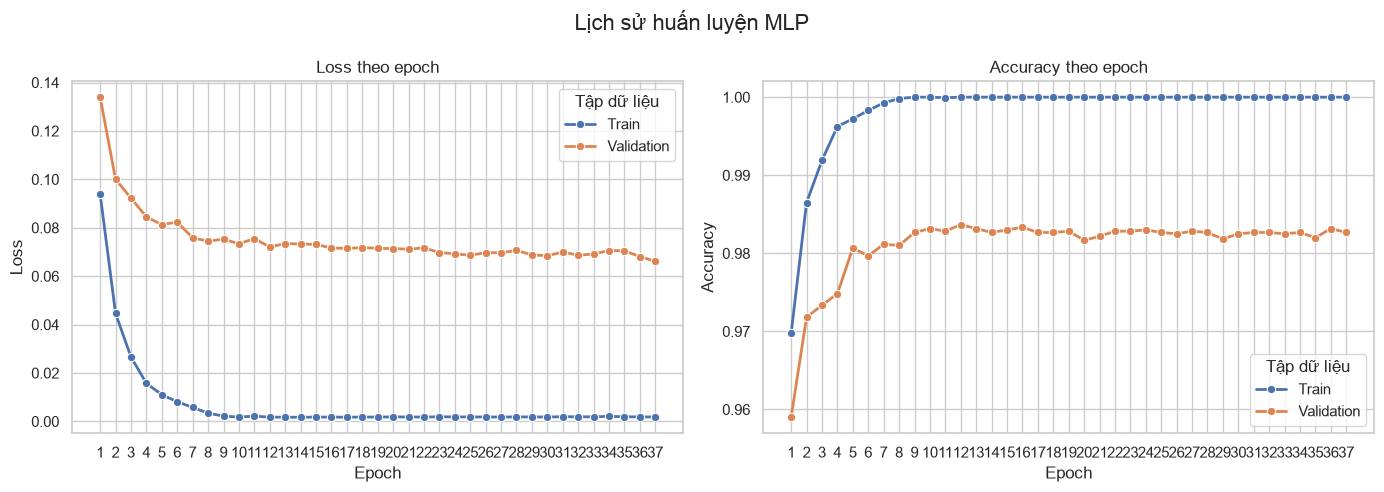

In [13]:
def plot_training_history(history):
    """Vẽ loss và accuracy theo từng epoch."""
    sns.set_theme(style="whitegrid", context="notebook")

    history_df = pd.DataFrame(history)
    history_df["epoch"] = range(1, len(history_df) + 1)

    plot_configs = [
        ("train_loss", "val_loss", "Loss"),
        ("train_acc", "val_acc", "Accuracy"),
    ]

    fig, axes = plt.subplots(ncols=2, figsize=(14, 5))

    for ax, (train_key, val_key, metric) in zip(axes, plot_configs):
        plot_df = history_df.melt(
            id_vars="epoch",
            value_vars=[train_key, val_key],
            var_name="dataset",
            value_name="value",
        )
        plot_df["dataset"] = plot_df["dataset"].map(
            {
                train_key: "Train",
                val_key: "Validation",
            }
        )

        sns.lineplot(
            data=plot_df,
            x="epoch",
            y="value",
            hue="dataset",
            marker="o",
            linewidth=2,
            ax=ax,
        )

        ax.set(
            title=f"{metric} theo epoch",
            xlabel="Epoch",
            ylabel=metric,
            xticks=history_df["epoch"],
        )
        ax.legend(title="Tập dữ liệu")

    fig.suptitle("Lịch sử huấn luyện MLP", fontsize=16)
    fig.tight_layout()
    plt.show()

plot_training_history(hist_mlp)

In [14]:
print(f"Thời gian huấn luyện MLP: {time_mlp_train:.3f} giây")
print(f"Thời gian dự đoán MLP: {time_mlp_pred:.3f} giây")

Thời gian huấn luyện MLP: 53.127 giây
Thời gian dự đoán MLP: 0.030 giây


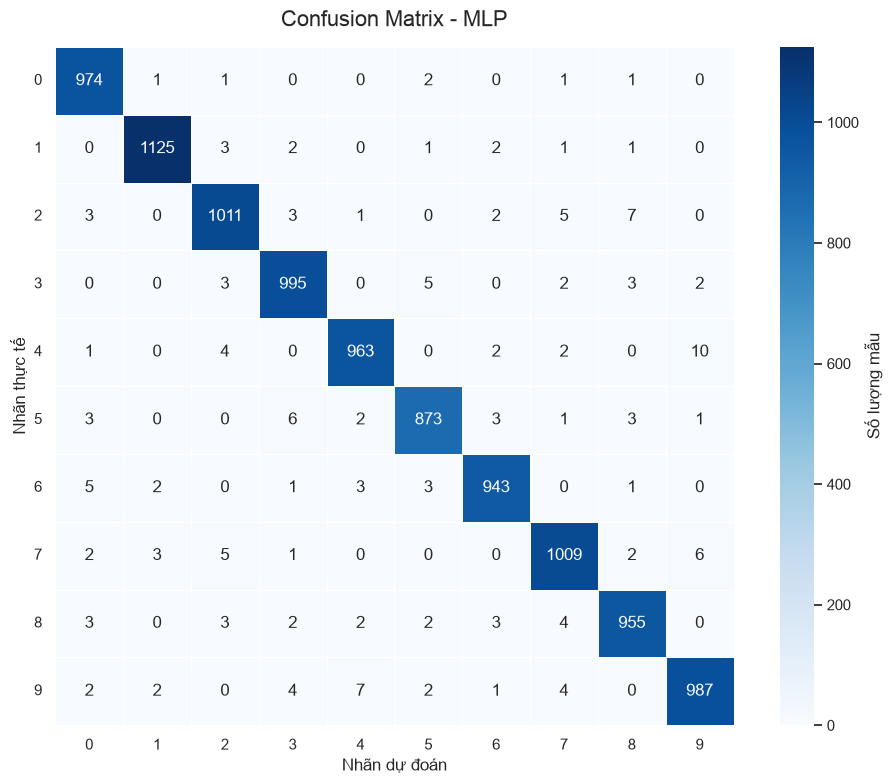

In [15]:
cm_mlp, class_names_mlp = metrics_mlp.get_confustion_matrix()

plot_confusion_matrix(
    cm=cm_mlp,
    class_names=class_names_mlp,
    title="Confusion Matrix - MLP",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
)

## ĐO DIVERSITY VÀ BUILD ENSEMBLE MODEL

In [16]:
def measure_diversity(y_pred_1, y_pred_2, y_true):
    """Đo diversity giữa hai mô hình phân loại.

    Parameters
    ----------
    y_pred_1 : array-like, shape (n_samples,)
        Nhãn dự đoán của mô hình thứ nhất.
    y_pred_2 : array-like, shape (n_samples,)
        Nhãn dự đoán của mô hình thứ hai.
    y_true : array-like, shape (n_samples,)
        Nhãn thực tế.

    Returns
    -------
    dict
        disagreement: Tỷ lệ 2 mô hình dự đoán nhãn khác nhau (trên toàn bộ tập test).
        double_fault: Tỷ lệ CẢ HAI cùng sai TRÊN SỐ ẢNH CÓ ÍT NHẤT 1 MÔ HÌNH SAI.
    """
    y_pred_1 = np.asarray(y_pred_1)
    y_pred_2 = np.asarray(y_pred_2)
    y_true = np.asarray(y_true)

    correct_1 = y_pred_1 == y_true
    correct_2 = y_pred_2 == y_true

    both_wrong = int(np.sum(~correct_1 & ~correct_2))
    
    at_least_one_wrong = int(np.sum(~correct_1 | ~correct_2))

    disagreement = float(np.mean(y_pred_1 != y_pred_2))

    if at_least_one_wrong == 0:
        double_fault = 0.0
    else:
        double_fault = both_wrong / at_least_one_wrong

    return {
        "disagreement": disagreement,
        "double_fault": double_fault,
        "both_wrong_count": both_wrong,
        "at_least_one_wrong_count": at_least_one_wrong,
    }

In [17]:
div_mlp_1 = measure_diversity(y_pred_lr, y_pred_mlp, y_test)
print(f"Double Fault: {div_mlp_1['double_fault']:.4f}")
print(f"Disagreement: {div_mlp_1['disagreement']:.4f}")
print(f"at_least_one_wrong_count : {div_mlp_1['at_least_one_wrong_count']}")
print(f"both_wrong_count: {div_mlp_1['both_wrong_count']}")

Double Fault: 0.1847
Disagreement: 0.0664
at_least_one_wrong_count : 769
both_wrong_count: 142


## TEST VỀ DIVERSITY CỦA CÁC MÔ HÌNH KHÁC

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

trained_models_en = {'model name' : [], 'models' : [], 'accuracy' : [], 'time train (s)': [], 'time pred (s)' : [], 'reports' : []}

TRAIN TỪNG MÔ HÌNH RIÊNG LẺ
Training Random Forest...


<>:37: SyntaxWarning: "\H" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\H"? A raw string is also an option.
<>:37: SyntaxWarning: "\H" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\H"? A raw string is also an option.
/tmp/ipykernel_10116/471587682.py:37: SyntaxWarning: "\H" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\H"? A raw string is also an option.
  print("\Hoàn tất training")


Training KNN...
\Hoàn tất training

ACCURACY TỪNG MÔ HÌNH
  MLP  | Accuracy: 0.9827 | Macro Recall: 0.9826
  RF   | Accuracy: 0.9670 | Macro Recall: 0.9669
  KNN  | Accuracy: 0.9723 | Macro Recall: 0.9719

ĐO DIVERSITY PAIRWISE
  MLP vs RF  | Double Fault: 0.3304 | Disagreement: 0.0282
  MLP vs KNN | Double Fault: 0.3366 | Disagreement: 0.0253
  RF vs MLP | Double Fault: 0.3304 | Disagreement: 0.0282
  RF vs KNN | Double Fault: 0.3188 | Disagreement: 0.0345
  KNN vs MLP | Double Fault: 0.3366 | Disagreement: 0.0253
  KNN vs RF  | Double Fault: 0.3188 | Disagreement: 0.0345

VISUALIZE DIVERSITY


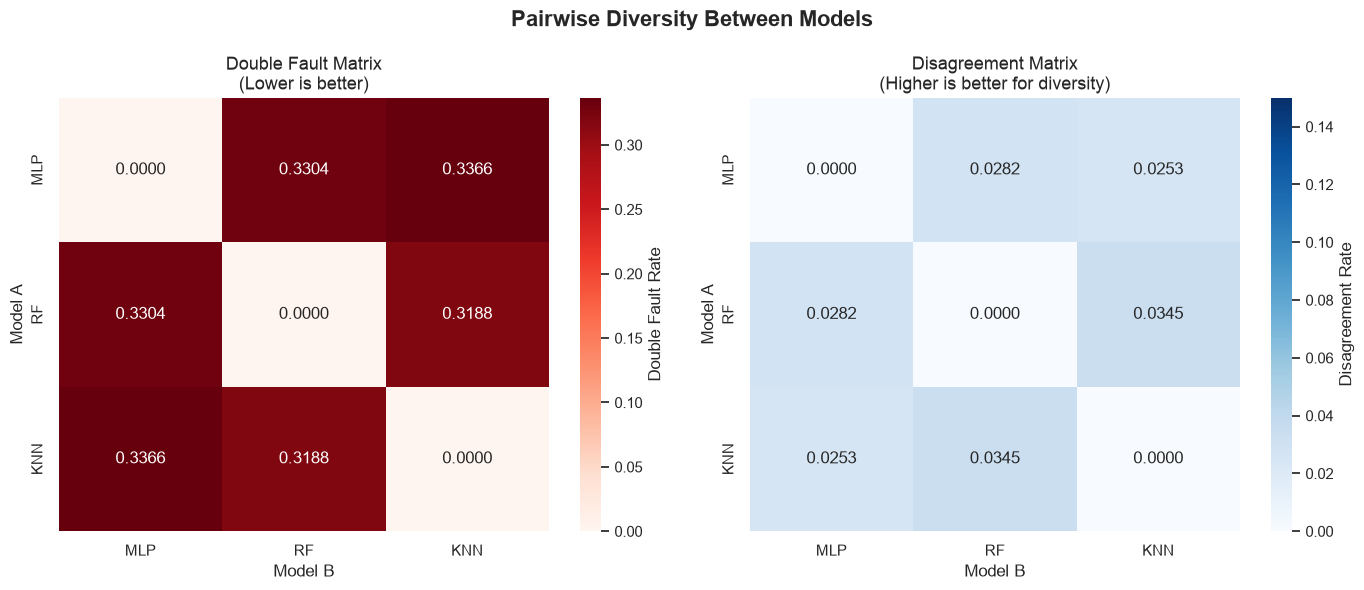

In [19]:
print("=" * 60)
print("TRAIN TỪNG MÔ HÌNH RIÊNG LẺ")
print("=" * 60)

# --- Random Forest ---
print("Training Random Forest...")
model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()
model_rf.fit(X_train, y_train)
time_rf_train = time.perf_counter() - start

y_pred_rf = model_rf.predict(X_val)

# --- KNN ---
print("Training KNN...")
model_knn = KNeighborsClassifier(
    n_neighbors=3,
    weights='distance',
    metric='euclidean',
    n_jobs=-1
)

start = time.perf_counter()
model_knn.fit(X_train, y_train)
time_knn_train = time.perf_counter() - start

y_pred_knn = model_knn.predict(X_val)


print("\Hoàn tất training")


print("\n" + "=" * 60)
print("ACCURACY TỪNG MÔ HÌNH")
print("=" * 60)

# dung lai model mlp da train o tren
y_pred_mlp_en = model_mlp.predict(X_val)

models = {
    'MLP': (model_mlp, y_pred_mlp_en),
    'RF':  (model_rf,  y_pred_rf),
    'KNN': (model_knn, y_pred_knn)
}

# lưu model và time train vào dict
trained_models_en['models'].append(model_mlp)
trained_models_en['models'].append(model_rf)
trained_models_en['models'].append(model_knn)
trained_models_en['time train (s)'].append(time_mlp_train)
trained_models_en['time train (s)'].append(time_rf_train)
trained_models_en['time train (s)'].append(time_knn_train)

for name, (_, y_pred) in models.items():
    metrics = ClassificationMetrics(y_pred=y_pred, y_true=y_val)
    report = metrics.evaluate()
    print(f"  {name:4s} | Accuracy: {report['accuracy']:.4f} | Macro Recall: {report['macro_recall']:.4f}")

# ĐO DIVERSITY PAIRWISE GIỮA CÁC MÔ HÌNH

print("\n" + "=" * 60)
print("ĐO DIVERSITY PAIRWISE")
print("=" * 60)

model_names = ['MLP', 'RF', 'KNN']
y_preds     = [y_pred_mlp_en, y_pred_rf, y_pred_knn]

# đánh giá diversity trên tập val data
n = len(model_names)
double_fault_mat   = np.zeros((n, n))
disagreement_mat   = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i == j:
            double_fault_mat[i, j] = 0.0
            disagreement_mat[i, j] = 0.0
        else:
            div = measure_diversity(y_preds[i], y_preds[j], y_val)
            double_fault_mat[i, j] = div['double_fault']
            disagreement_mat[i, j] = div['disagreement']
            print(f"  {model_names[i]} vs {model_names[j]:3s} | "
                  f"Double Fault: {div['double_fault']:.4f} | "
                  f"Disagreement: {div['disagreement']:.4f}")


# VISUALIZE DIVERSITY MATRIX

print("\n" + "=" * 60)
print("VISUALIZE DIVERSITY")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Pairwise Diversity Between Models", fontsize=16, fontweight='bold')

# --- Heatmap 1: Double Fault ---
sns.heatmap(
    double_fault_mat,
    annot=True,
    fmt='.4f',
    cmap='Reds',
    xticklabels=model_names,
    yticklabels=model_names,
    ax=axes[0],
    cbar_kws={'label': 'Double Fault Rate'},
    vmin=0, vmax=max(double_fault_mat.max(), 0.05)
)
axes[0].set_title("Double Fault Matrix\n(Lower is better)", fontsize=13)
axes[0].set_xlabel("Model B")
axes[0].set_ylabel("Model A")

# --- Heatmap 2: Disagreement ---

sns.heatmap(
    disagreement_mat,
    annot=True,
    fmt='.4f',
    cmap='Blues',
    xticklabels=model_names,
    yticklabels=model_names,
    ax=axes[1],
    cbar_kws={'label': 'Disagreement Rate'},
    vmin=0, vmax=max(disagreement_mat.max(), 0.15)
)
axes[1].set_title("Disagreement Matrix\n(Higher is better for diversity)", fontsize=13)
axes[1].set_xlabel("Model B")
axes[1].set_ylabel("Model A")

plt.tight_layout()
plt.show()

## Dự đoán các model trên tập test hoàn toàn chưa đc nhìn thấy

In [20]:
# lưu lại thời gian dự đoán / suy luận
start = time.perf_counter() 
y_pred_mlp_en = models['MLP'][0].predict(X_test)
time_mlp_pred = time.perf_counter() - start

start = time.perf_counter() 
y_pred_rf = models['RF'][0].predict(X_test)
time_rf_pred = time.perf_counter() - start

start = time.perf_counter() 
y_pred_knn = models['KNN'][0].predict(X_test)
time_knn_pred = time.perf_counter() - start

dict_models = {
    'MLP' : y_pred_mlp_en,
    'RF': y_pred_rf,
    'KNN': y_pred_knn
}

trained_models_en['time pred (s)'].append(time_mlp_pred)
trained_models_en['time pred (s)'].append(time_rf_pred)
trained_models_en['time pred (s)'].append(time_knn_pred)

for name, (y_pred) in dict_models.items():
    metrics = ClassificationMetrics(y_pred=y_pred, y_true=y_test)
    report = metrics.evaluate()
    print(f"  {name:4s} | Accuracy: {report['accuracy']:.4f} | Macro Recall: {report['macro_recall']:.4f}")

    # lưu lại accuracy trên tập test
    trained_models_en['accuracy'].append(report['accuracy'])
    trained_models_en['reports'].append(report)
    trained_models_en['model name'].append(name)

  MLP  | Accuracy: 0.9835 | Macro Recall: 0.9834
  RF   | Accuracy: 0.9690 | Macro Recall: 0.9687
  KNN  | Accuracy: 0.9709 | Macro Recall: 0.9706


### Kết luận & Đánh giá Diversity

* **Tổng quan:** Ba mô hình (MLP, RF, KNN) có tính đa dạng (diversity) đủ để ensemble có lợi. Các mô hình có những lỗi khác nhau, cho thấy tiềm năng bù trừ lỗi. Hiệu quả kết hợp được kiểm chứng bằng accuracy trên validation.
* **Cặp đôi tốt nhất:** **MLP vs KNN** có chỉ số trùng lỗi thấp nhất (`Double Fault = 30.05%`), cho thấy khả năng bù trừ lỗi cho nhau tốt nhất.
* **Cặp trùng lỗi nhiều nhất:** **RF vs MLP** (`Double Fault = 34.73%`), do cả hai đều có xu hướng sai ở những vùng dữ liệu khó tương tự nhau.
* **Hiệu quả Ensemble:** Việc kết hợp `RF + KNN + MLP` là một phương án hợp lý để cải thiện về accuracy.

## SỬ DỤNG SOFT VOTTING RANDOM FOREST + KNN + MLP (cấu hình đầu tiên)
- Từ thí nghiệm trên, cho thấy sự kết hợp giữa 3 models này có triển vọng trong việc cải thiện về accuracy.

In [21]:
class CustomSoftVotingEnsemble:
    def __init__(self, weights=None):
        """
        Args:
            mlp_model: Instance của mô hình MLP.
            weights: List trọng số [mlp_w, rf_w, knn_w].
        """
        self.mlp = MLP(
            sizes=best_config_mlp['sizes'],
            activation='relu',
            p_drop=best_config_mlp['p_drop'],
            init='he',
            seed=SEED
        )
        self.weights = np.asarray(
            [3, 1, 1] if weights is None else weights,
            dtype=float,
        )
        
        # Khởi tạo RF và KNN
        self.rf = RandomForestClassifier(
            n_estimators=200, max_depth=None, min_samples_split=5, 
            random_state=42, n_jobs=-1
        )

        self.knn = KNeighborsClassifier(
            n_neighbors=3, weights='distance', metric='euclidean', 
            n_jobs=-1
        )

    def fit(self, X_train, y_train, X_val, y_val, patience = 4):
        """Huấn luyện cả 3 mô hình: MLP, RF và KNN."""
        print("Đang train MLP...")
        self.mlp.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=best_config_mlp['max_epochs'],
            batch_size=best_config_mlp['batch_size'],
            lr=best_config_mlp['lr'],
            patience=best_config_mlp['patience'],  # early stopping
            weight_decay=best_config_mlp['weight_decay'],
            momentum=best_config_mlp['momentum'],
            seed=SEED,
            verbose=True
        )
        print(f"Train xong mlp: sizes = {best_config_mlp['sizes']}, activation = relu, p_dropout = {best_config_mlp['p_drop']}, init = he")
        print("Đang train Random Forest và KNN...")
        self.rf.fit(X_train, y_train)
        self.knn.fit(X_train, y_train)
        print(f"Train xong RF: {self.rf}")
        print(f"Train xong KNN: {self.knn}")
        print("Hoàn tất fitting toàn bộ Ensemble.")
        return self

    def predict_proba(self, X):
        """Tính trung bình có trọng số (weighted average) của xác suất."""
        # Lấy xác suất dự đoán từ từng mô hình
        proba_mlp = self.mlp.predict_proba(X)
        proba_rf = self.rf.predict_proba(X)
        proba_knn = self.knn.predict_proba(X)
        
        # Chuẩn hóa weights để tổng bằng 1
        norm_weights = np.array(self.weights) / sum(self.weights)
        
        # Soft voting: cộng dồn xác suất theo trọng số
        ensemble_proba = (
            norm_weights[0] * proba_mlp +
            norm_weights[1] * proba_rf +
            norm_weights[2] * proba_knn
        )
        return ensemble_proba

    def predict(self, X):
        """Dự đoán nhãn cuối cùng dựa trên xác suất cao nhất."""
        return np.argmax(self.predict_proba(X), axis=1)

In [38]:
ensemble = CustomSoftVotingEnsemble(
    weights=[2, 1, 1]
)

start = time.perf_counter()
ensemble.fit(
    X_train,
    y_train,
    patience=4,
    X_val=X_val,
    y_val=y_val  # early stopping
)
time_ensemble_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_ens = ensemble.predict(X_test)
time_ensemble_pred = time.perf_counter() - start

metrics_ens = ClassificationMetrics(y_pred=y_pred_ens, y_true=y_test)
report_ens = metrics_ens.evaluate()

trained_models_en['models'].append(ensemble)
trained_models_en['model name'].append('Ensemble (MLP + RF + KNN)')
trained_models_en['accuracy'].append(report_ens['accuracy'])
trained_models_en['reports'].append(report_ens)
trained_models_en['time train (s)'].append(time_ensemble_train)
trained_models_en['time pred (s)'].append(time_ensemble_pred)

Đang train MLP...
Epoch 01/37 | train loss 0.0939 acc 0.9697 | val loss 0.1340 acc 0.9590
Epoch 02/37 | train loss 0.0446 acc 0.9865 | val loss 0.1000 acc 0.9718
Epoch 03/37 | train loss 0.0266 acc 0.9919 | val loss 0.0922 acc 0.9733
Epoch 04/37 | train loss 0.0157 acc 0.9962 | val loss 0.0845 acc 0.9748
Epoch 05/37 | train loss 0.0110 acc 0.9972 | val loss 0.0813 acc 0.9807
Epoch 06/37 | train loss 0.0081 acc 0.9983 | val loss 0.0824 acc 0.9797
Epoch 07/37 | train loss 0.0058 acc 0.9993 | val loss 0.0758 acc 0.9812
Epoch 08/37 | train loss 0.0034 acc 0.9998 | val loss 0.0745 acc 0.9810
Epoch 09/37 | train loss 0.0022 acc 1.0000 | val loss 0.0753 acc 0.9827
Epoch 10/37 | train loss 0.0018 acc 1.0000 | val loss 0.0733 acc 0.9832
Epoch 11/37 | train loss 0.0022 acc 0.9999 | val loss 0.0755 acc 0.9828
Epoch 12/37 | train loss 0.0018 acc 1.0000 | val loss 0.0720 acc 0.9837
Epoch 13/37 | train loss 0.0017 acc 1.0000 | val loss 0.0735 acc 0.9832
Epoch 14/37 | train loss 0.0017 acc 1.0000 | v

/tmp/ipykernel_10116/1636677723.py:68: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  norm_weights[0] * proba_mlp +


In [39]:
print(f"Ensemble Accuracy : {report_ens['accuracy']:.4f}")
print(f"Macro Recall      : {report_ens['macro_recall']:.4f}")
print(f"Time Train: {time_ensemble_train}")
print(f"Time Test: {time_ensemble_pred}")

Ensemble Accuracy : 0.9848
Macro Recall      : 0.9847
Time Train: 59.01496610600043
Time Test: 6.020659338999394


In [40]:
from IPython.display import display

def show_results(data):
    df = pd.DataFrame({
        "Mô hình": data["model name"],
        "Accuracy": data["accuracy"],
        "Macro Recall": [r["macro_recall"] for r in data["reports"]],
        "Macro F1": [r["macro_f1"] for r in data["reports"]],
        "Train (s)": data["time train (s)"],
        "Predict (s)": data["time pred (s)"],
    })

    metrics = ["Accuracy", "Macro Recall", "Macro F1"]
    times = ["Train (s)", "Predict (s)"]

    df[metrics + times] = df[metrics + times].astype(float)
    df = df.sort_values("Accuracy", ascending=False)

    display(
        df.style
        .hide(axis="index")
        .format({
            **{col: "{:.2%}" for col in metrics},
            **{col: "{:.3f}" for col in times},
        })
        .highlight_max(subset=metrics, color="#166534")
        .highlight_min(subset=times, color="#166534")
    )

In [41]:
len(trained_models_en['accuracy']), len(trained_models['accuracy'])

(7, 3)

In [42]:
show_results(trained_models_en)

Mô hình,Accuracy,Macro Recall,Macro F1,Train (s),Predict (s)
Ensemble (MLP + RF + KNN),98.48%,98.47%,98.47%,62.024,6.003
Ensemble (MLP + RF + KNN),98.48%,98.47%,98.47%,59.015,6.021
Ensemble (MLP + RF + KNN),98.43%,98.42%,98.42%,60.480,6.813
MLP,98.35%,98.34%,98.34%,53.127,0.043
Ensemble (MLP + RF + KNN),98.34%,98.33%,98.34%,60.427,5.903
KNN,97.09%,97.06%,97.07%,0.016,6.007
RF,96.90%,96.87%,96.87%,10.457,0.201


In [43]:
show_results(trained_models)

Mô hình,Accuracy,Macro Recall,Macro F1,Train (s),Predict (s)
MLP,98.35%,98.34%,98.34%,53.127,0.030
Logistic Regression,92.54%,92.43%,92.43%,6.208,0.024
Naive Bayess,81.49%,81.12%,81.33%,0.414,0.428


## LƯU TRỌNG SỐ CỦA CÁC MÔ HÌNH

In [44]:
import torch
import joblib
import json

## LƯU MODEL

In [45]:
# Thiết lập đường dẫn thư mục models tại thư mục gốc hiện tại
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)  # Tự động tạo thư mục nếu chưa tồn tại

print(f"Đang lưu mô hình vào thư mục: {MODELS_DIR.absolute()}")

if 'ensemble' in locals():
    ens_dir = MODELS_DIR / "ensemble_v1"
    ens_dir.mkdir(exist_ok=True)  # Tạo thư mục con ensemble_v1
    
    # Lưu MLP trong ensemble
    torch.save({
        'model_state_dict': ensemble.mlp.model.state_dict(),
        'config': {'sizes': ensemble.mlp.sizes, 'activation': 'relu', 'p_drop': best_config_mlp['p_drop'], 'init': 'he' , 'seed' : SEED}
    }, ens_dir / "mlp_part.pth")
    
    # Lưu RF và KNN bằng joblib
    joblib.dump(ensemble.rf, ens_dir / "rf_part.joblib")
    joblib.dump(ensemble.knn, ens_dir / "knn_part.joblib")
    
    # Lưu weights voting
    with open(ens_dir / "config.json", "w") as f:
        # Chuyển numpy array sang list thường để json lưu được
        json.dump({"weights": ensemble.weights.tolist()}, f)
        
    print(f"Đã lưu Ensemble tại thư mục: {ens_dir}/")

if 'model_nb' in locals():
    nb_path = MODELS_DIR / "naive_bayes.joblib"
    joblib.dump(model_nb, nb_path)
    print(f"Đã lưu Naive Bayes tại: {nb_path}")

print("\nHOÀN TẤT LƯU TRỮ!")

Đang lưu mô hình vào thư mục: /home/nguyenhaianh/Desktop/Classify_Number/models
Đã lưu Ensemble tại thư mục: /home/nguyenhaianh/Desktop/Classify_Number/models/ensemble_v1/
Đã lưu Naive Bayes tại: /home/nguyenhaianh/Desktop/Classify_Number/models/naive_bayes.joblib

HOÀN TẤT LƯU TRỮ!
